In [2]:
import os
import re
import cv2
import time
import math
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

!pip -q install ultralytics

from pathlib import Path
from tqdm import tqdm
from ultralytics import YOLO
from collections import defaultdict

import xml.etree.ElementTree as ET
import shutil

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 24.8 MB/s eta 0:00:00a 0:00:01
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


# Dataset

In [1]:
# ================================================
# CONFIGURATION
# Classe finale
FINAL_CLASSES = ["car"]

# UA-DETRAC types autorisés
KEEP_TYPES = ["car", "van"]   # fusionnés
IGNORE_TYPES = ["bus", "others"]

# Paths
#ann_train = "/kaggle/input/ua-detrac-orig/DETRAC-Train-Annotations-XML/DETRAC-Train-Annotations-XML"
ann_val   = "/kaggle/input/datasets/bratjay/ua-detrac-orig/DETRAC-Test-Annotations-XML/DETRAC-Test-Annotations-XML"
img_root  = "/kaggle/input/datasets/bratjay/ua-detrac-orig/DETRAC-Images/DETRAC-Images"

out_images_train = "data/images/train"
out_labels_train = "data/labels/train"
out_images_val   = "data/images/val"
out_labels_val   = "data/labels/val"

for d in [
    out_images_train, out_labels_train,
    out_images_val, out_labels_val
]:
    os.makedirs(d, exist_ok=True)

# ==================================================
# CLASS MAPPING
# ==================================================

def map_vehicle_type(vtype):
    """
    car  -> 0
    van  -> 0
    bus / others -> ignored
    """
    if vtype in KEEP_TYPES:
        return 0
    return None

# ==================================================
# CONVERSION BOX
# ==================================================

def convert_to_yolo(left, top, width, height, img_w, img_h):
    xmin = float(left)
    ymin = float(top)
    xmax = xmin + float(width)
    ymax = ymin + float(height)

    return (
        ((xmin + xmax) / 2) / img_w,
        ((ymin + ymax) / 2) / img_h,
        (xmax - xmin) / img_w,
        (ymax - ymin) / img_h
    )

# ==================================================
# XML PROCESSING
# ==================================================

def process_xml(xml_path, mode="train"):
    tree = ET.parse(xml_path)
    root = tree.getroot()

    seq_name = root.attrib["name"]
    img_dir = os.path.join(img_root, seq_name)

    out_img_dir = out_images_train if mode == "train" else out_images_val
    out_lbl_dir = out_labels_train if mode == "train" else out_labels_val

    for frame in root.findall("frame"):
        frame_num = int(frame.attrib["num"])

        # Ici, on garde toutes les frames
        img_name = f"img{frame_num:05d}.jpg"
        img_path = os.path.join(img_dir, img_name)

        if not os.path.exists(img_path):
            continue

        img = cv2.imread(img_path)
        if img is None:
            continue

        h, w = img.shape[:2]

        target_list = frame.find("target_list")
        label_lines = []

        if target_list is not None:
            for obj in target_list.findall("target"):
                attr = obj.find("attribute")
                if attr is None:
                    continue

                vtype = attr.attrib.get("vehicle_type")
                cls_id = map_vehicle_type(vtype)

                if cls_id is None:
                    continue

                box = obj.find("box")
                if box is None:
                    continue

                x, y, bw, bh = convert_to_yolo(
                    box.attrib["left"],
                    box.attrib["top"],
                    box.attrib["width"],
                    box.attrib["height"],
                    w, h
                )

                label_lines.append(
                    f"{cls_id} {x:.6f} {y:.6f} {bw:.6f} {bh:.6f}"
                )

        out_name = f"{seq_name}_img{frame_num:05d}"

        # écrire label même vide
        with open(os.path.join(out_lbl_dir, out_name + ".txt"), "w") as f:
            if label_lines:
                f.write("\n".join(label_lines))

        dst_img = os.path.join(out_img_dir, out_name + ".jpg")
        if not os.path.exists(dst_img):
            shutil.copy(img_path, dst_img)

# ==================================================
# EXECUTION
# ==================================================

print("Conversion VAL sans frame sampling...")
for xml_file in glob(os.path.join(ann_val, "*.xml")):
    process_xml(xml_file, mode="val")

print("Dataset YOLO UA-DETRAC prêt sans frame stride.")

Conversion VAL sans frame sampling...
Dataset YOLO UA-DETRAC prêt sans frame stride.


# CONFIGURATION

In [3]:
DATASET_DIR = Path("/kaggle/working/data")

IMG_VAL_DIR = DATASET_DIR / "images" / "val"
LBL_VAL_DIR = DATASET_DIR / "labels" / "val"

MODEL_PATH = "/kaggle/input/models/chaymaeramii/modelname/other/default/1/best.pt"

# Car-only model
NUM_CLASSES = 1
CLASS_NAMES = {0: "car"}

IMG_SIZE = 768
CONF_THRES = 0.30     
IOU_NMS = 0.60

# Event / adaptive
K_MIN = 1
K_MAX = 5
N_MAX_CARS = 20

# Pour ne pas overfitter les seuils sur toute la validation
CALIBRATION_SEQUENCE_RATIO = 0.20

RESULTS_DIR = Path("/kaggle/working/ua_detrac_event_adaptive_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Images val:", IMG_VAL_DIR)
print("Labels val:", LBL_VAL_DIR)
print("Model:", MODEL_PATH)
print("Results:", RESULTS_DIR)

Images val: /kaggle/working/data/images/val
Labels val: /kaggle/working/data/labels/val
Model: /kaggle/input/models/chaymaeramii/modelname/other/default/1/best.pt
Results: /kaggle/working/ua_detrac_event_adaptive_results


In [4]:
def list_images_recursive(img_dir):
    exts = ["*.jpg", "*.jpeg", "*.png", "*.bmp"]
    files = []
    for ext in exts:
        files.extend(img_dir.rglob(ext))
    return sorted(files)


def image_id(path):
    return Path(path).stem


def extract_frame_number(path):
    stem = Path(path).stem
    nums = re.findall(r"\d+", stem)
    if len(nums) == 0:
        return 0
    return int(nums[-1])


def infer_sequence_id(path, root_dir):
    """
    UA-DETRAC est normalement organisé par séquences MVI_xxxx.
    Si les images sont dans des dossiers, le parent devient la séquence.
    Sinon, on essaie d'extraire MVI_xxxx du nom.
    """
    path = Path(path)
    rel = path.relative_to(root_dir)

    if len(rel.parts) > 1:
        return rel.parts[0]

    stem = path.stem

    m = re.search(r"(MVI[_-]?\d+)", stem, re.IGNORECASE)
    if m:
        return m.group(1)

    # fallback : préfixe avant le dernier numéro
    seq = re.sub(r"[_-]?\d+$", "", stem)
    if seq == "":
        seq = "single_stream"

    return seq


def build_sequences(img_dir):
    images = list_images_recursive(img_dir)
    sequences = defaultdict(list)

    for p in images:
        sid = infer_sequence_id(p, img_dir)
        sequences[sid].append(p)

    ordered_sequences = {}
    for sid, paths in sequences.items():
        ordered_sequences[sid] = sorted(paths, key=extract_frame_number)

    return ordered_sequences


sequences = build_sequences(IMG_VAL_DIR)

print("Nombre de séquences:", len(sequences))
print("Nombre total images:", sum(len(v) for v in sequences.values()))

for sid, paths in list(sequences.items())[:5]:
    print(sid, ":", len(paths), "frames", "ex:", paths[0].name)

Nombre de séquences: 40
Nombre total images: 56167
MVI_39031 : 1470 frames ex: MVI_39031_img00001.jpg
MVI_39051 : 1051 frames ex: MVI_39051_img00001.jpg
MVI_39211 : 1566 frames ex: MVI_39211_img00001.jpg
MVI_39271 : 1566 frames ex: MVI_39271_img00001.jpg
MVI_39311 : 1505 frames ex: MVI_39311_img00001.jpg


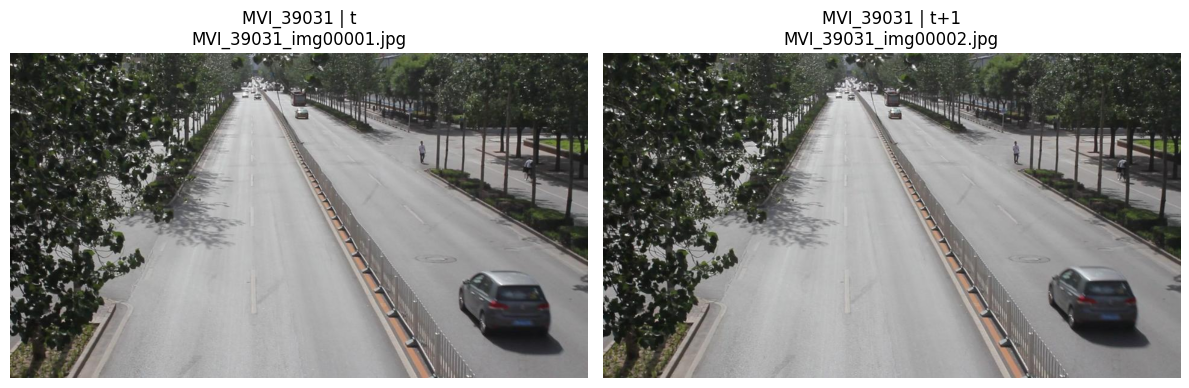

In [5]:
def show_t_t1(sequence_id=None, idx=0):
    if sequence_id is None:
        sequence_id = list(sequences.keys())[0]

    paths = sequences[sequence_id]

    img_t_path = paths[idx]
    img_t1_path = paths[idx + 1]

    img_t = cv2.imread(str(img_t_path))
    img_t1 = cv2.imread(str(img_t1_path))

    img_t = cv2.cvtColor(img_t, cv2.COLOR_BGR2RGB)
    img_t1 = cv2.cvtColor(img_t1, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img_t)
    plt.title(f"{sequence_id} | t\n{img_t_path.name}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(img_t1)
    plt.title(f"{sequence_id} | t+1\n{img_t1_path.name}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


show_t_t1(idx=0)

# Calibration

In [6]:
def load_image_shape(img_path):
    img = cv2.imread(str(img_path))
    if img is None:
        raise ValueError(f"Image non lisible: {img_path}")
    h, w = img.shape[:2]
    return h, w



def find_label_path(img_path, img_root, label_root):
    """
    Cherche le .txt correspondant à une image.
    Supporte :
    - labels/val/sequence/frame.txt
    - labels/val/frame.txt
    """
    img_path = Path(img_path)
    rel = img_path.relative_to(img_root)

    candidate1 = label_root / rel.with_suffix(".txt")
    if candidate1.exists():
        return candidate1

    candidate2 = label_root / f"{img_path.stem}.txt"
    if candidate2.exists():
        return candidate2

    return candidate1



def yolo_label_to_xyxy(label_path, img_w, img_h):
    """
    YOLO label:
    cls xc yc w h
    Retour:
    [cls, x1, y1, x2, y2]
    """
    boxes = []

    if not Path(label_path).exists():
        return np.zeros((0, 5), dtype=np.float32)

    with open(label_path, "r") as f:
        lines = f.readlines()

    for line in lines:
        parts = line.strip().split()
        if len(parts) < 5:
            continue

        cls = int(float(parts[0]))
        xc, yc, bw, bh = map(float, parts[1:5])

        x1 = (xc - bw / 2) * img_w
        y1 = (yc - bh / 2) * img_h
        x2 = (xc + bw / 2) * img_w
        y2 = (yc + bh / 2) * img_h

        x1 = max(0, min(img_w - 1, x1))
        y1 = max(0, min(img_h - 1, y1))
        x2 = max(0, min(img_w - 1, x2))
        y2 = max(0, min(img_h - 1, y2))

        boxes.append([cls, x1, y1, x2, y2])

    return np.array(boxes, dtype=np.float32)


In [7]:
sequence_ids = sorted(list(sequences.keys()))

n_calib = max(1, int(len(sequence_ids) * CALIBRATION_SEQUENCE_RATIO))

calib_seq_ids = sequence_ids[:n_calib]
eval_seq_ids = sequence_ids[n_calib:]

if len(eval_seq_ids) == 0:
    eval_seq_ids = calib_seq_ids

print("Calibration sequences:", len(calib_seq_ids))
print("Evaluation sequences:", len(eval_seq_ids))

print("Calib examples:", calib_seq_ids[:5])
print("Eval examples:", eval_seq_ids[:5])

Calibration sequences: 8
Evaluation sequences: 32
Calib examples: ['MVI_39031', 'MVI_39051', 'MVI_39211', 'MVI_39271', 'MVI_39311']
Eval examples: ['MVI_39501', 'MVI_39511', 'MVI_40701', 'MVI_40711', 'MVI_40712']


In [8]:
def flatten_sequences(seq_ids):
    out = []
    for sid in seq_ids:
        for p in sequences[sid]:
            out.append((sid, p))
    return out


calib_stream = flatten_sequences(calib_seq_ids)
eval_stream = flatten_sequences(eval_seq_ids)

print("Calibration frames:", len(calib_stream))
print("Evaluation frames:", len(eval_stream))

Calibration frames: 11963
Evaluation frames: 44204


In [9]:
def read_gray_small(img_path, size=(160, 90)):
    img = cv2.imread(str(img_path))
    if img is None:
        raise ValueError(f"Image non lisible: {img_path}")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, size)
    gray = gray.astype(np.float32) / 255.0

    return gray


def compute_visual_delta(img_path_t, img_path_prev):
    g_t = read_gray_small(img_path_t)
    g_prev = read_gray_small(img_path_prev)
    return float(np.mean(np.abs(g_t - g_prev)))


def compute_delta_cache(stream):
    """
    Delta par image.
    Si nouvelle séquence, delta = 1 pour forcer une inférence.
    """
    delta_cache = {}

    prev_sid = None
    prev_path = None

    for sid, img_path in tqdm(stream, desc="Computing visual deltas"):
        img_key = f"{sid}/{img_path.stem}"

        if prev_sid != sid or prev_path is None:
            delta_cache[img_key] = 1.0
        else:
            delta_cache[img_key] = compute_visual_delta(img_path, prev_path)

        prev_sid = sid
        prev_path = img_path

    return delta_cache


all_stream = flatten_sequences(sequence_ids)
delta_cache = compute_delta_cache(all_stream)

delta_values = np.array(list(delta_cache.values()))


Computing visual deltas: 100%|██████████| 56167/56167 [05:06<00:00, 183.00it/s]


In [10]:
model = YOLO(MODEL_PATH)

In [11]:
def run_yolo_single(model, img_path):
    """
    Retourne:
    preds = [x1, y1, x2, y2, conf, cls]
    latency en secondes
    """
    start = time.perf_counter()

    results = model.predict(
        source=str(img_path),
        imgsz=IMG_SIZE,
        conf=CONF_THRES,
        iou=IOU_NMS,
        verbose=False
    )

    latency = time.perf_counter() - start
    r = results[0]

    if r.boxes is None or len(r.boxes) == 0:
        return np.zeros((0, 6), dtype=np.float32), latency

    xyxy = r.boxes.xyxy.cpu().numpy()
    conf = r.boxes.conf.cpu().numpy().reshape(-1, 1)
    cls = r.boxes.cls.cpu().numpy().reshape(-1, 1)

    preds = np.concatenate([xyxy, conf, cls], axis=1).astype(np.float32)
    return preds, latency


def make_key(sid, img_path):
    return f"{sid}/{Path(img_path).stem}"


def build_cache(stream):
    pred_cache = {}
    gt_cache = {}
    latency_cache = {}
    shape_cache = {}

    for sid, img_path in tqdm(stream, desc="YOLO cache"):
        key = make_key(sid, img_path)

        h, w = load_image_shape(img_path)
        label_path = find_label_path(img_path, IMG_VAL_DIR, LBL_VAL_DIR)

        gt = yolo_label_to_xyxy(label_path, w, h)
        preds, latency = run_yolo_single(model, img_path)

        pred_cache[key] = preds
        gt_cache[key] = gt
        latency_cache[key] = latency
        shape_cache[key] = (h, w)

    return pred_cache, gt_cache, latency_cache, shape_cache


pred_cache, gt_cache, latency_cache, shape_cache = build_cache(all_stream)

print("Mean YOLO latency:", np.mean(list(latency_cache.values())) * 1000, "ms")
print("Median YOLO latency:", np.median(list(latency_cache.values())) * 1000, "ms")

YOLO cache: 100%|██████████| 56167/56167 [15:13<00:00, 61.50it/s]

Mean YOLO latency: 13.203208961613058 ms
Median YOLO latency: 12.998420000258193 ms


# RAED_VP Functions

In [12]:
def box_iou_np(box, boxes):
    if boxes.shape[0] == 0:
        return np.zeros((0,), dtype=np.float32)

    x1 = np.maximum(box[0], boxes[:, 0])
    y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2])
    y2 = np.minimum(box[3], boxes[:, 3])

    inter = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)

    area_box = np.maximum(0, box[2] - box[0]) * np.maximum(0, box[3] - box[1])
    area_boxes = np.maximum(0, boxes[:, 2] - boxes[:, 0]) * np.maximum(0, boxes[:, 3] - boxes[:, 1])

    union = area_box + area_boxes - inter + 1e-9
    return inter / union


def compute_ap(recall, precision):
    mrec = np.concatenate(([0.0], recall, [1.0]))
    mpre = np.concatenate(([1.0], precision, [0.0]))

    for i in range(mpre.size - 1, 0, -1):
        mpre[i - 1] = np.maximum(mpre[i - 1], mpre[i])

    x = np.linspace(0, 1, 101)
    ap = np.trapz(np.interp(x, mrec, mpre), x)
    return float(ap)


def evaluate_class_ap(preds_by_key, gt_by_key, cls_id=0, iou_thr=0.5):
    gt_for_class = {}
    n_gt = 0

    for key, gt in gt_by_key.items():
        gtc = gt[gt[:, 0] == cls_id][:, 1:5] if len(gt) else np.zeros((0, 4))
        gt_for_class[key] = {
            "boxes": gtc,
            "matched": np.zeros((gtc.shape[0],), dtype=bool)
        }
        n_gt += gtc.shape[0]

    preds = []
    for key, pred in preds_by_key.items():
        if pred.shape[0] == 0:
            continue

        pc = pred[pred[:, 5] == cls_id]
        for row in pc:
            preds.append((key, float(row[4]), row[:4]))

    if n_gt == 0:
        return None

    if len(preds) == 0:
        return 0.0

    preds = sorted(preds, key=lambda x: x[1], reverse=True)

    tp = np.zeros(len(preds))
    fp = np.zeros(len(preds))

    for i, (key, conf, box) in enumerate(preds):
        gt_boxes = gt_for_class[key]["boxes"]
        matched = gt_for_class[key]["matched"]

        if gt_boxes.shape[0] == 0:
            fp[i] = 1
            continue

        ious = box_iou_np(box, gt_boxes)
        best_idx = int(np.argmax(ious))
        best_iou = ious[best_idx]

        if best_iou >= iou_thr and not matched[best_idx]:
            tp[i] = 1
            matched[best_idx] = True
        else:
            fp[i] = 1

    tp_cum = np.cumsum(tp)
    fp_cum = np.cumsum(fp)

    recall = tp_cum / (n_gt + 1e-9)
    precision = tp_cum / (tp_cum + fp_cum + 1e-9)

    return compute_ap(recall, precision)


def evaluate_map(preds_by_key, gt_by_key):
    ap50 = evaluate_class_ap(preds_by_key, gt_by_key, cls_id=0, iou_thr=0.50)

    iou_thresholds = np.arange(0.50, 0.96, 0.05)
    aps = []

    for thr in iou_thresholds:
        ap = evaluate_class_ap(preds_by_key, gt_by_key, cls_id=0, iou_thr=thr)
        if ap is not None:
            aps.append(ap)

    return {
        "mAP50": float(ap50 if ap50 is not None else 0.0),
        "mAP50_95": float(np.mean(aps) if len(aps) else 0.0)
    }


def compute_prf1(preds_by_key, gt_by_key, iou_thr=0.5):
    total_tp = 0
    total_fp = 0
    total_fn = 0

    for key, gt in gt_by_key.items():
        pred = preds_by_key.get(key, np.zeros((0, 6), dtype=np.float32))

        gt_boxes = gt[gt[:, 0] == 0][:, 1:5] if len(gt) else np.zeros((0, 4))
        pred_boxes = pred[pred[:, 5] == 0][:, :4] if len(pred) else np.zeros((0, 4))

        matched = np.zeros((gt_boxes.shape[0],), dtype=bool)

        if pred_boxes.shape[0] == 0:
            total_fn += gt_boxes.shape[0]
            continue

        for pb in pred_boxes:
            if gt_boxes.shape[0] == 0:
                total_fp += 1
                continue

            ious = box_iou_np(pb, gt_boxes)
            best_idx = int(np.argmax(ious))
            best_iou = ious[best_idx]

            if best_iou >= iou_thr and not matched[best_idx]:
                total_tp += 1
                matched[best_idx] = True
            else:
                total_fp += 1

        total_fn += int(np.sum(~matched))

    precision = total_tp / (total_tp + total_fp + 1e-9)
    recall = total_tp / (total_tp + total_fn + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)

    return {
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "tp": int(total_tp),
        "fp": int(total_fp),
        "fn": int(total_fn)
    }

In [13]:
def count_mae(preds_by_key, gt_by_key):
    errors = []
    for key, gt in gt_by_key.items():
        pred = preds_by_key.get(key, np.zeros((0, 6), dtype=np.float32))
        n_gt = int(np.sum(gt[:, 0] == 0)) if len(gt) else 0
        n_pred = int(np.sum(pred[:, 5] == 0)) if len(pred) else 0
        errors.append(abs(n_pred - n_gt))

    return float(np.mean(errors)) if len(errors) else 0.0


def temporal_count_stability(stream, preds_by_key):
    """
    Stability proche de 1 = nombre de voitures stable entre frames successives.
    """
    values = []

    prev_sid = None
    prev_count = None

    for sid, img_path in stream:
        key = make_key(sid, img_path)
        pred = preds_by_key.get(key, np.zeros((0, 6), dtype=np.float32))
        count = int(np.sum(pred[:, 5] == 0)) if len(pred) else 0

        if prev_sid == sid and prev_count is not None:
            denom = max(count, prev_count, 1)
            stability = 1.0 - abs(count - prev_count) / denom
            values.append(stability)

        prev_sid = sid
        prev_count = count

    return float(np.mean(values)) if len(values) else 0.0

In [14]:
def vehicle_density_score(preds, n_max=N_MAX_CARS):
    if preds is None or preds.shape[0] == 0:
        return 0.0

    n = int(np.sum(preds[:, 5] == 0))
    return float(min(n / n_max, 1.0))


def uncertainty_score(preds):
    """
    Si aucune voiture détectée, on met une incertitude moyenne.
    """
    if preds is None or preds.shape[0] == 0:
        return 0.50

    confs = preds[preds[:, 5] == 0][:, 4]

    if len(confs) == 0:
        return 0.50

    return float(1.0 - np.mean(confs))


def normalize_delta(delta, delta_ref):
    return float(min(delta / (delta_ref + 1e-9), 1.0))


def adaptive_risk(delta, last_preds, alpha, beta, gamma, delta_ref):
    d = normalize_delta(delta, delta_ref)
    dens = vehicle_density_score(last_preds)
    unc = uncertainty_score(last_preds)

    r = alpha * d + beta * dens + gamma * unc
    return float(np.clip(r, 0.0, 1.0))


def dynamic_interval_from_risk(risk, k_min=1, k_max=5):
    k = k_max - math.floor((k_max - k_min) * risk)
    return int(np.clip(k, k_min, k_max))

In [23]:
def subset_caches(stream):
    keys = [make_key(sid, p) for sid, p in stream]

    pred_sub = {k: pred_cache[k] for k in keys}
    gt_sub = {k: gt_cache[k] for k in keys}
    latency_sub = {k: latency_cache[k] for k in keys}

    return pred_sub, gt_sub, latency_sub


def build_continuous(stream):
    preds_by_key = {}
    infer_flags = {}

    for sid, img_path in stream:
        key = make_key(sid, img_path)
        preds_by_key[key] = pred_cache[key]
        infer_flags[key] = 1

    return preds_by_key, infer_flags


def build_event_driven(stream, theta, max_skip):
    """
    Event-driven:
    - inférence si delta > theta
    - ou si max_skip atteint
    - sinon propagation dernière prédiction
    """
    preds_by_key = {}
    infer_flags = {}

    prev_sid = None
    last_preds = None
    skipped = 0

    for idx, (sid, img_path) in enumerate(stream):
        key = make_key(sid, img_path)
        delta = delta_cache[key]

        new_sequence = sid != prev_sid

        run = False

        if new_sequence:
            run = True
        elif delta > theta:
            run = True
        elif skipped >= max_skip:
            run = True

        if run:
            preds = pred_cache[key]
            last_preds = preds
            skipped = 0
            infer_flags[key] = 1
        else:
            preds = last_preds if last_preds is not None else np.zeros((0, 6), dtype=np.float32)
            skipped += 1
            infer_flags[key] = 0

        preds_by_key[key] = preds
        prev_sid = sid

    return preds_by_key, infer_flags


def build_adaptive(stream, alpha, beta, gamma, delta_ref, k_max, force_dense_if_cars=True):
    """
    Adaptive:
    - calcule R_t
    - déduit K_t
    - si beaucoup de voitures, force plus d'inférence
    """
    preds_by_key = {}
    infer_flags = {}
    risk_cache = {}
    k_cache = {}

    prev_sid = None
    last_preds = None
    frames_since_infer = 999

   

    for idx, (sid, img_path) in enumerate(stream):
        key = make_key(sid, img_path)
        delta = delta_cache[key]

        new_sequence = sid != prev_sid

        if new_sequence:
            risk = 1.0
            k_t = 1
            run = True
        else:
            risk = adaptive_risk(
                delta=delta,
                last_preds=last_preds,
                alpha=alpha,
                beta=beta,
                gamma=gamma,
                delta_ref=delta_ref
            )

            k_t = dynamic_interval_from_risk(risk, k_min=K_MIN, k_max=k_max)

            # idée intelligente: si scène dense, ne pas trop skipper
            density = vehicle_density_score(last_preds)

            if force_dense_if_cars and density >= 0.50:
                k_t = min(k_t, 2)

            run = frames_since_infer >= k_t
            

        if run:
            preds = pred_cache[key]
            last_preds = preds
            frames_since_infer = 0
            infer_flags[key] = 1
        else:
            preds = last_preds if last_preds is not None else np.zeros((0, 6), dtype=np.float32)
            frames_since_infer += 1
            infer_flags[key] = 0

        preds_by_key[key] = preds
        risk_cache[key] = risk
        k_cache[key] = k_t

        prev_sid = sid

    return preds_by_key, infer_flags, risk_cache, k_cache




In [16]:
def summarize_policy(policy_name, stream, preds_by_key, infer_flags, gt_by_key, latency_by_key, trigger_latency_per_frame=0.001):
    n_total = len(infer_flags)
    n_yolo = int(sum(infer_flags.values()))
    n_skip = n_total - n_yolo

    map_res = evaluate_map(preds_by_key, gt_by_key)
    prf = compute_prf1(preds_by_key, gt_by_key, iou_thr=0.5)

    yolo_time = sum(latency_by_key[k] for k, flag in infer_flags.items() if flag == 1)
    trigger_time = n_total * trigger_latency_per_frame
    total_time = yolo_time + trigger_time

    count_error = count_mae(preds_by_key, gt_by_key)
    stability = temporal_count_stability(stream, preds_by_key)

    return {
        "policy": policy_name,
        "mAP50": map_res["mAP50"],
        "mAP50_95": map_res["mAP50_95"],
        "precision": prf["precision"],
        "recall": prf["recall"],
        "f1": prf["f1"],
        "count_MAE": count_error,
        "temporal_stability": stability,
        "total_frames": n_total,
        "yolo_frames": n_yolo,
        "skipped_frames": n_skip,
        "frames_processed_ratio": n_yolo / max(n_total, 1),
        "frame_reduction": 1.0 - n_yolo / max(n_total, 1),
        "estimated_total_time_s": total_time,
        "estimated_yolo_time_s": yolo_time,
        "mean_latency_per_frame_ms": 1000 * total_time / max(n_total, 1),
        "effective_fps": n_total / max(total_time, 1e-9)
    }

In [18]:
def score_policy(summary, continuous_summary, lambda_cost=0.15, lambda_count=0.02, epsilon_recall=0.02, penalty_weight=3.0):
    """
    Score scientifique:
    - mAP élevé
    - coût faible
    - count_MAE faible
    - pénalité si recall chute trop par rapport au continuous
    """
    map_score = summary["mAP50_95"]
    cost = summary["frames_processed_ratio"]
    count_penalty = lambda_count * summary["count_MAE"]

    recall_loss = continuous_summary["recall"] - summary["recall"]
    recall_penalty = max(0.0, recall_loss - epsilon_recall) * penalty_weight

    score = map_score - lambda_cost * cost - count_penalty - recall_penalty
    return float(score)

# Continuous

In [17]:
calib_pred_base, calib_gt, calib_latency = subset_caches(calib_stream)
eval_pred_base, eval_gt, eval_latency = subset_caches(eval_stream)

calib_cont_preds, calib_cont_flags = build_continuous(calib_stream)
eval_cont_preds, eval_cont_flags = build_continuous(eval_stream)

calib_cont_summary = summarize_policy(
    "Continuous",
    calib_stream,
    calib_cont_preds,
    calib_cont_flags,
    calib_gt,
    calib_latency
)

eval_cont_summary = summarize_policy(
    "Continuous",
    eval_stream,
    eval_cont_preds,
    eval_cont_flags,
    eval_gt,
    eval_latency
)

pd.DataFrame([calib_cont_summary, eval_cont_summary])

/tmp/ipykernel_57/4064674785.py:27: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ap = np.trapz(np.interp(x, mrec, mpre), x)


,policy,mAP50,mAP50_95,precision,recall,f1,count_MAE,temporal_stability,total_frames,yolo_frames,skipped_frames,frames_processed_ratio,frame_reduction,estimated_total_time_s,estimated_yolo_time_s,mean_latency_per_frame_ms,effective_fps
0,Continuous,0.805083,0.628369,0.500633,0.935696,0.652274,5.390537,0.929239,11963,11963,0,1.0,0.0,170.694176,158.731176,14.268509,70.084406
1,Continuous,0.849673,0.648072,0.716588,0.850690,0.777902,3.759931,0.944652,44204,44204,0,1.0,0.0,627.057462,582.853462,14.185537,70.494337


# Event-Driven ( Calibration )

In [19]:
theta_candidates = [
    float(np.percentile(delta_values, 50)),
    float(np.percentile(delta_values, 60)),
    float(np.percentile(delta_values, 70)),
    float(np.percentile(delta_values, 80)),
    float(np.percentile(delta_values, 90)),
]

max_skip_candidates = [2, 3, 4, 6]
#max_skip_candidates = [3]
event_rows = []

for theta in theta_candidates:
    for max_skip in max_skip_candidates:
        preds, flags = build_event_driven(
            calib_stream,
            theta=theta,
            max_skip=max_skip
        )

        summary = summarize_policy(
            f"Event_theta_{theta:.4f}_skip_{max_skip}",
            calib_stream,
            preds,
            flags,
            calib_gt,
            calib_latency
        )

        summary["theta"] = theta
        summary["max_skip"] = max_skip
        summary["score"] = score_policy(summary, calib_cont_summary)

        event_rows.append(summary)

event_grid = pd.DataFrame(event_rows).sort_values("score", ascending=False)
event_grid.head(10)

/tmp/ipykernel_57/4064674785.py:27: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ap = np.trapz(np.interp(x, mrec, mpre), x)


,policy,mAP50,mAP50_95,precision,recall,f1,count_MAE,temporal_stability,total_frames,yolo_frames,skipped_frames,frames_processed_ratio,frame_reduction,estimated_total_time_s,estimated_yolo_time_s,mean_latency_per_frame_ms,effective_fps,theta,max_skip,score
12,Event_theta_0.0210_skip_2,0.804240,0.584370,0.500160,0.934416,0.651562,5.386442,0.954435,11963,7130,4833,0.596004,0.403996,107.558383,95.595383,8.990921,111.223316,0.020989,2,0.387240
8,Event_theta_0.0178_skip_2,0.804604,0.596970,0.500086,0.934708,0.651570,5.390955,0.949009,11963,8198,3765,0.685280,0.314720,121.574663,109.611663,10.162556,98.400438,0.017806,2,0.386359
4,Event_theta_0.0157_skip_2,0.804723,0.604780,0.500417,0.934569,0.651817,5.382011,0.944918,11963,8934,3029,0.746803,0.253197,131.164091,119.201091,10.964147,91.206366,0.015744,2,0.385120
16,Event_theta_0.0257_skip_2,0.804620,0.562634,0.500324,0.934151,0.651637,5.380925,0.962080,11963,5637,6326,0.471203,0.528797,87.875515,75.912515,7.345609,136.135760,0.025684,2,0.384335
0,Event_theta_0.0140_skip_2,0.804796,0.611721,0.500551,0.934819,0.651992,5.382346,0.941109,11963,9605,2358,0.802892,0.197108,139.935652,127.972652,11.697371,85.489293,0.014011,2,0.383640
1,Event_theta_0.0140_skip_3,0.803016,0.603092,0.499918,0.933539,0.651143,5.381342,0.942142,11963,9383,2580,0.784335,0.215665,137.039570,125.076570,11.455285,87.295954,0.014011,3,0.377815
5,Event_theta_0.0157_skip_3,0.801640,0.592609,0.499743,0.932510,0.650744,5.372565,0.946363,11963,8664,3299,0.724233,0.275767,127.623493,115.660493,10.668185,93.736661,0.015744,3,0.376523
9,Event_theta_0.0178_skip_3,0.799940,0.580052,0.498968,0.931494,0.649840,5.378082,0.950830,11963,7822,4141,0.653849,0.346151,116.669895,104.706895,9.752562,102.537162,0.017806,3,0.374413
2,Event_theta_0.0140_skip_4,0.798154,0.595889,0.497967,0.930117,0.648655,5.384017,0.943074,11963,9260,2703,0.774053,0.225947,135.436523,123.473523,11.321284,88.329202,0.014011,4,0.372101
13,Event_theta_0.0210_skip_3,0.798140,0.560505,0.497860,0.930590,0.648680,5.392962,0.957561,11963,6621,5342,0.553456,0.446544,100.958141,88.995141,8.439199,118.494654,0.020989,3,0.369627


In [21]:
best_event = event_grid.iloc[0].to_dict()
best_event

{'policy': 'Event_theta_0.0210_skip_2',
 'mAP50': 0.8042400600414478,
 'mAP50_95': 0.5843698731847389,
 'precision': 0.5001601096192333,
 'recall': 0.9344157379968426,
 'f1': 0.651561893220625,
 'count_MAE': 5.386441528044805,
 'temporal_stability': 0.9544352485894338,
 'total_frames': 11963,
 'yolo_frames': 7130,
 'skipped_frames': 4833,
 'frames_processed_ratio': 0.5960043467357686,
 'frame_reduction': 0.40399565326423137,
 'estimated_total_time_s': 107.55838281799905,
 'estimated_yolo_time_s': 95.59538281799905,
 'mean_latency_per_frame_ms': 8.990920573267497,
 'effective_fps': 111.22331599427959,
 'theta': 0.020989054068922996,
 'max_skip': 2,
 'score': 0.3872403906134775}

# Adaptive ( Calibration )

In [24]:
adaptive_rows = []

weight_sets = [
    (0.40, 0.35, 0.25),
    (0.45, 0.35, 0.20),
    (0.35, 0.45, 0.20),
    (0.50, 0.30, 0.20),
    (0.50, 0.40, 0.10),
    (0.30, 0.50, 0.20),
]

delta_refs = [
    float(np.percentile(delta_values, 60)),
    float(np.percentile(delta_values, 70)),
    float(np.percentile(delta_values, 80)),
    float(np.percentile(delta_values, 90)),
]

kmax_candidates = [3, 4, 5, 6]


for alpha, beta, gamma in weight_sets:
    print("(alpha, beta, gamma)")
    for delta_ref in delta_refs:
        print("deltaRef --->" , delta_ref)
        for kmax in kmax_candidates:
            preds, flags, risks, ks = build_adaptive(
                calib_stream,
                alpha=alpha,
                beta=beta,
                gamma=gamma,
                delta_ref=delta_ref,
                k_max=kmax,
                force_dense_if_cars=True
            )

            summary = summarize_policy(
                f"Adaptive_a{alpha}_b{beta}_g{gamma}_k{kmax}",
                calib_stream,
                preds,
                flags,
                calib_gt,
                calib_latency
            )

            summary["alpha"] = alpha
            summary["beta"] = beta
            summary["gamma"] = gamma
            summary["delta_ref"] = delta_ref
            summary["kmax"] = kmax
            summary["score"] = score_policy(summary, calib_cont_summary)

            adaptive_rows.append(summary)

adaptive_grid = pd.DataFrame(adaptive_rows).sort_values("score", ascending=False)
adaptive_grid.head(10)

(alpha, beta, gamma)
deltaRef ---> 0.01574389934539795


/tmp/ipykernel_57/4064674785.py:27: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ap = np.trapz(np.interp(x, mrec, mpre), x)


deltaRef ---> 0.017805610224604605
deltaRef ---> 0.020989054068922996
deltaRef ---> 0.025683552771806718
(alpha, beta, gamma)
deltaRef ---> 0.01574389934539795
deltaRef ---> 0.017805610224604605
deltaRef ---> 0.020989054068922996
deltaRef ---> 0.025683552771806718
(alpha, beta, gamma)
deltaRef ---> 0.01574389934539795
deltaRef ---> 0.017805610224604605
deltaRef ---> 0.020989054068922996
deltaRef ---> 0.025683552771806718
(alpha, beta, gamma)
deltaRef ---> 0.01574389934539795
deltaRef ---> 0.017805610224604605
deltaRef ---> 0.020989054068922996
deltaRef ---> 0.025683552771806718
(alpha, beta, gamma)
deltaRef ---> 0.01574389934539795
deltaRef ---> 0.017805610224604605
deltaRef ---> 0.020989054068922996
deltaRef ---> 0.025683552771806718
(alpha, beta, gamma)
deltaRef ---> 0.01574389934539795
deltaRef ---> 0.017805610224604605
deltaRef ---> 0.020989054068922996
deltaRef ---> 0.025683552771806718


,policy,mAP50,mAP50_95,precision,recall,f1,count_MAE,temporal_stability,total_frames,yolo_frames,...,estimated_total_time_s,estimated_yolo_time_s,mean_latency_per_frame_ms,effective_fps,alpha,beta,gamma,delta_ref,kmax,score
64,Adaptive_a0.5_b0.4_g0.1_k3,0.803519,0.533884,0.498803,0.933317,0.650143,5.402240,0.972030,11963,3929,...,65.296740,53.333740,5.458224,183.209760,0.50,0.40,0.10,0.015744,3,0.376575
68,Adaptive_a0.5_b0.4_g0.1_k3,0.802988,0.533026,0.498562,0.933275,0.649928,5.407005,0.971980,11963,3895,...,64.918560,52.955560,5.426612,184.277040,0.50,0.40,0.10,0.017806,3,0.376048
48,Adaptive_a0.5_b0.3_g0.2_k3,0.803099,0.533281,0.498729,0.933484,0.650120,5.406253,0.971667,11963,3927,...,65.286935,53.323935,5.457405,183.237273,0.50,0.30,0.20,0.015744,3,0.375916
52,Adaptive_a0.5_b0.3_g0.2_k3,0.802799,0.532639,0.498442,0.932677,0.649681,5.402993,0.971935,11963,3898,...,64.927040,52.964040,5.427321,184.252971,0.50,0.30,0.20,0.017806,3,0.375703
16,Adaptive_a0.45_b0.35_g0.2_k3,0.801985,0.531923,0.497969,0.932802,0.649309,5.414862,0.971488,11963,3904,...,65.005296,53.042296,5.433862,184.031160,0.45,0.35,0.20,0.015744,3,0.374675
20,Adaptive_a0.45_b0.35_g0.2_k3,0.801775,0.530105,0.497916,0.932371,0.649160,5.415698,0.971419,11963,3873,...,64.568480,52.605480,5.397348,185.276159,0.45,0.35,0.20,0.017806,3,0.373229
0,Adaptive_a0.4_b0.35_g0.25_k3,0.801063,0.529178,0.497851,0.931508,0.648895,5.407089,0.971566,11963,3837,...,64.112289,52.149289,5.359215,186.594493,0.40,0.35,0.25,0.015744,3,0.372925
56,Adaptive_a0.5_b0.3_g0.2_k3,0.801696,0.529101,0.497941,0.931995,0.649090,5.408092,0.972386,11963,3840,...,64.169240,52.206240,5.363976,186.428887,0.50,0.30,0.20,0.020989,3,0.372791
72,Adaptive_a0.5_b0.4_g0.1_k3,0.801162,0.528452,0.497519,0.931925,0.648715,5.416116,0.971965,11963,3841,...,64.176223,52.213223,5.364559,186.408602,0.50,0.40,0.10,0.020989,3,0.371969
24,Adaptive_a0.45_b0.35_g0.2_k3,0.800272,0.527436,0.497753,0.930868,0.648657,5.400401,0.971841,11963,3808,...,63.746603,51.783603,5.328647,187.664901,0.45,0.35,0.20,0.020989,3,0.371681


In [25]:
best_adaptive = adaptive_grid.iloc[0].to_dict()
best_adaptive

{'policy': 'Adaptive_a0.5_b0.4_g0.1_k3',
 'mAP50': 0.8035186439031792,
 'mAP50_95': 0.5338840382564788,
 'precision': 0.49880288497285674,
 'recall': 0.9333166381457081,
 'f1': 0.6501427064710625,
 'count_MAE': 5.402240240742289,
 'temporal_stability': 0.9720304408637807,
 'total_frames': 11963,
 'yolo_frames': 3929,
 'skipped_frames': 8034,
 'frames_processed_ratio': 0.3284293237482237,
 'frame_reduction': 0.6715706762517764,
 'estimated_total_time_s': 65.29673965298551,
 'estimated_yolo_time_s': 53.333739652985514,
 'mean_latency_per_frame_ms': 5.45822449661335,
 'effective_fps': 183.20975999071993,
 'alpha': 0.5,
 'beta': 0.4,
 'gamma': 0.1,
 'delta_ref': 0.01574389934539795,
 'kmax': 3,
 'score': 0.37657483487939947}

# Evaluation

In [26]:
# Continuous
eval_cont_preds, eval_cont_flags = build_continuous(eval_stream)

final_cont = summarize_policy(
    "Continuous",
    eval_stream,
    eval_cont_preds,
    eval_cont_flags,
    eval_gt,
    eval_latency
)

# Best Event
eval_event_preds, eval_event_flags = build_event_driven(
    eval_stream,
    theta=float(best_event["theta"]),
    max_skip=int(best_event["max_skip"])
)

final_event = summarize_policy(
    "Event-driven",
    eval_stream,
    eval_event_preds,
    eval_event_flags,
    eval_gt,
    eval_latency
)

# Best Adaptive
eval_adapt_preds, eval_adapt_flags, eval_adapt_risks, eval_adapt_ks = build_adaptive(
    eval_stream,
    alpha=float(best_adaptive["alpha"]),
    beta=float(best_adaptive["beta"]),
    gamma=float(best_adaptive["gamma"]),
    delta_ref=float(best_adaptive["delta_ref"]),
    k_max=int(best_adaptive["kmax"]),
    force_dense_if_cars=True
)

final_adapt = summarize_policy(
    "Adaptive",
    eval_stream,
    eval_adapt_preds,
    eval_adapt_flags,
    eval_gt,
    eval_latency
)

final_df = pd.DataFrame([final_cont, final_event, final_adapt])

continuous_time = final_df.loc[final_df["policy"] == "Continuous", "estimated_total_time_s"].values[0]
continuous_map = final_df.loc[final_df["policy"] == "Continuous", "mAP50_95"].values[0]
continuous_recall = final_df.loc[final_df["policy"] == "Continuous", "recall"].values[0]

final_df["time_reduction_vs_continuous"] = 1.0 - final_df["estimated_total_time_s"] / continuous_time
final_df["energy_proxy_reduction"] = final_df["time_reduction_vs_continuous"]
final_df["mAP50_95_drop"] = continuous_map - final_df["mAP50_95"]
final_df["recall_drop"] = continuous_recall - final_df["recall"]

final_df = final_df[
    [
        "policy",
        "mAP50",
        "mAP50_95",
        "precision",
        "recall",
        "f1",
        "count_MAE",
        "temporal_stability",
        "total_frames",
        "yolo_frames",
        "skipped_frames",
        "frames_processed_ratio",
        "frame_reduction",
        "mean_latency_per_frame_ms",
        "effective_fps",
        "time_reduction_vs_continuous",
        "energy_proxy_reduction",
        "mAP50_95_drop",
        "recall_drop"
    ]
]

final_df

/tmp/ipykernel_57/4064674785.py:27: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ap = np.trapz(np.interp(x, mrec, mpre), x)


,policy,mAP50,mAP50_95,precision,recall,f1,count_MAE,temporal_stability,total_frames,yolo_frames,skipped_frames,frames_processed_ratio,frame_reduction,mean_latency_per_frame_ms,effective_fps,time_reduction_vs_continuous,energy_proxy_reduction,mAP50_95_drop,recall_drop
0,Continuous,0.849673,0.648072,0.716588,0.850690,0.777902,3.759931,0.944652,44204,44204,0,1.000000,0.000000,14.185537,70.494337,0.000000,0.000000,0.000000,0.000000
1,Event-driven,0.848605,0.610808,0.715418,0.849475,0.776705,3.762578,0.972830,44204,18381,25823,0.415822,0.584178,6.483537,154.236792,0.542947,0.542947,0.037264,0.001215
2,Adaptive,0.848198,0.599103,0.715128,0.848885,0.776287,3.754592,0.977428,44204,14320,29884,0.323953,0.676047,5.271260,189.707979,0.628406,0.628406,0.048969,0.001805


In [27]:
def compute_latency_statistics(infer_flags, latency_cache, trigger_latency_per_frame=0.001):
    """
    Compute per-frame latency statistics for one inference policy.

    Parameters
    ----------
    infer_flags : dict
        key -> 1 if YOLO was executed, 0 if prediction was propagated.
    latency_cache : dict
        key -> measured YOLO latency in seconds.
    trigger_latency_per_frame : float
        Lightweight event-analysis latency per frame in seconds.

    Returns
    -------
    dict with mean, median, p95, p99 in milliseconds.
    """
    frame_latencies = []

    for key, flag in infer_flags.items():
        if flag == 1:
            latency = latency_cache[key] + trigger_latency_per_frame
        else:
            latency = trigger_latency_per_frame

        frame_latencies.append(latency * 1000.0)  # seconds -> ms

    frame_latencies = np.array(frame_latencies, dtype=np.float32)

    return {
        "mean_ms": float(np.mean(frame_latencies)),
        "median_ms": float(np.median(frame_latencies)),
        "p95_ms": float(np.percentile(frame_latencies, 95)),
        "p99_ms": float(np.percentile(frame_latencies, 99)),
        "min_ms": float(np.min(frame_latencies)),
        "max_ms": float(np.max(frame_latencies)),
    }


lat_cont = compute_latency_statistics(
    eval_cont_flags,
    eval_latency,
    trigger_latency_per_frame=0.001
)

lat_event = compute_latency_statistics(
    eval_event_flags,
    eval_latency,
    trigger_latency_per_frame=0.001
)

lat_adapt = compute_latency_statistics(
    eval_adapt_flags,
    eval_latency,
    trigger_latency_per_frame=0.001
)

latency_stats_df = pd.DataFrame([
    {"policy": "Continuous", **lat_cont},
    {"policy": "Event-driven", **lat_event},
    {"policy": "Adaptive", **lat_adapt},
])

display(latency_stats_df)

latency_stats_df.to_csv(RESULTS_DIR / "latency_statistics.csv", index=False)
print("Saved:", RESULTS_DIR / "latency_statistics.csv")

,policy,mean_ms,median_ms,p95_ms,p99_ms,min_ms,max_ms
0,Continuous,14.185536,14.006349,15.380798,17.219061,13.091456,36.476604
1,Event-driven,6.483537,1.000000,14.692518,15.879198,1.000000,26.980581
2,Adaptive,5.271259,1.000000,14.535807,15.740649,1.000000,25.219164


Saved: /kaggle/working/ua_detrac_event_adaptive_results/latency_statistics.csv


# ABLATION STUDY: RAED-VP RISK COMPONENTS

In [32]:
ablation_configs = [
    {
        "variant": "Visual only",
        "components": "Scene variation",
        "alpha": 1.0,
        "beta": 0.0,
        "gamma": 0.0
    },
    {
        "variant": "Density only",
        "components": "Vehicle density",
        "alpha": 0.0,
        "beta": 1.0,
        "gamma": 0.0
    },
    {
        "variant": "Uncertainty only",
        "components": "Detector uncertainty",
        "alpha": 0.0,
        "beta": 0.0,
        "gamma": 1.0
    },
    {
        "variant": "Visual + Density",
        "components": "Scene variation + vehicle density",
        "alpha": 0.5,
        "beta": 0.5,
        "gamma": 0.0
    },
    {
        "variant": "Full RAED-VP",
        "components": "Scene variation + vehicle density + uncertainty",
        "alpha": 0.50,
        "beta": 0.4,
        "gamma": 0.1
    }
]

# Use the same delta_ref and kmax as your best adaptive policy
best_delta_ref = float(best_adaptive["delta_ref"])
best_kmax = int(best_adaptive["kmax"])

ablation_rows = []

for cfg in ablation_configs:
    preds, flags, risks, ks = build_adaptive(
        eval_stream,
        alpha=cfg["alpha"],
        beta=cfg["beta"],
        gamma=cfg["gamma"],
        delta_ref=best_delta_ref,
        k_max=best_kmax,
        force_dense_if_cars=True
    )

    summary = summarize_policy(
        cfg["variant"],
        eval_stream,
        preds,
        flags,
        eval_gt,
        eval_latency
    )

    summary["components"] = cfg["components"]
    summary["alpha"] = cfg["alpha"]
    summary["beta"] = cfg["beta"]
    summary["gamma"] = cfg["gamma"]

    ablation_rows.append(summary)

ablation_df = pd.DataFrame(ablation_rows)

# Add useful drops compared with continuous
continuous_map50 = final_cont["mAP50"]
continuous_recall = final_cont["recall"]
continuous_time = final_cont["estimated_total_time_s"]

ablation_df["mAP50_drop"] = continuous_map50 - ablation_df["mAP50"]
ablation_df["recall_drop"] = continuous_recall - ablation_df["recall"]
ablation_df["time_reduction_vs_continuous"] = 1.0 - ablation_df["estimated_total_time_s"] / continuous_time

ablation_df = ablation_df[
    [
        "policy",
        "components",
        "alpha",
        "beta",
        "gamma",
        "mAP50",
        "mAP50_95",
        "precision",
        "recall",
        "f1",
        "count_MAE",
        "temporal_stability",
        "yolo_frames",
        "skipped_frames",
        "frames_processed_ratio",
        "frame_reduction",
        "mean_latency_per_frame_ms",
        "effective_fps",
        "mAP50_drop",
        "recall_drop",
        "time_reduction_vs_continuous"
    ]
]

display(ablation_df)

ablation_df.to_csv(RESULTS_DIR / "ablation_risk_components.csv", index=False)
print("Saved:", RESULTS_DIR / "ablation_risk_components.csv")

/tmp/ipykernel_57/4064674785.py:27: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ap = np.trapz(np.interp(x, mrec, mpre), x)


,policy,components,alpha,beta,gamma,mAP50,mAP50_95,precision,recall,f1,...,temporal_stability,yolo_frames,skipped_frames,frames_processed_ratio,frame_reduction,mean_latency_per_frame_ms,effective_fps,mAP50_drop,recall_drop,time_reduction_vs_continuous
0,Visual only,Scene variation,1.0,0.0,0.0,0.848868,0.614680,0.715601,0.849386,0.776775,...,0.974647,16948,27256,0.383404,0.616596,6.055080,165.150593,0.000805,0.001304,0.573151
1,Density only,Vehicle density,0.0,1.0,0.0,0.846197,0.603213,0.714228,0.846969,0.774955,...,0.977195,15073,29131,0.340987,0.659013,5.494849,181.988636,0.003476,0.003721,0.612644
2,Uncertainty only,Detector uncertainty,0.0,0.0,1.0,0.846161,0.594433,0.714084,0.846979,0.774875,...,0.978777,13577,30627,0.307144,0.692856,5.049773,198.028714,0.003512,0.003711,0.644020
3,Visual + Density,Scene variation + vehicle density,0.5,0.5,0.0,0.848469,0.604538,0.715523,0.848823,0.776493,...,0.976984,14940,29264,0.337978,0.662022,5.456630,183.263289,0.001204,0.001867,0.615338
4,Full RAED-VP,Scene variation + vehicle density + uncertainty,0.5,0.4,0.1,0.848198,0.599103,0.715128,0.848885,0.776287,...,0.977428,14320,29884,0.323953,0.676047,5.271260,189.707979,0.001475,0.001805,0.628406


Saved: /kaggle/working/ua_detrac_event_adaptive_results/ablation_risk_components.csv


# SENSITIVITY ANALYSIS: Kmax

In [43]:
kmax_values = [3, 4, 5, 6 , 7 , 8]

# Use best RAED-VP weights
alpha = float(best_adaptive["alpha"])
beta = float(best_adaptive["beta"])
gamma = float(best_adaptive["gamma"])
delta_ref = float(best_adaptive["delta_ref"])

kmax_rows = []

for kmax in kmax_values:
    preds, flags, risks, ks = build_adaptive(
        eval_stream,
        alpha=alpha,
        beta=beta,
        gamma=gamma,
        delta_ref=delta_ref,
        k_max=kmax,
        force_dense_if_cars=True
    )

    summary = summarize_policy(
        f"Adaptive_Kmax_{kmax}",
        eval_stream,
        preds,
        flags,
        eval_gt,
        eval_latency
    )

    summary["Kmax"] = kmax
    summary["alpha"] = alpha
    summary["beta"] = beta
    summary["gamma"] = gamma
    summary["delta_ref"] = delta_ref

    kmax_rows.append(summary)

kmax_df = pd.DataFrame(kmax_rows)

# Drops compared with continuous
continuous_map50 = final_cont["mAP50"]
continuous_map5095 = final_cont["mAP50_95"]
continuous_recall = final_cont["recall"]
continuous_time = final_cont["estimated_total_time_s"]
continuous_latency = final_cont["mean_latency_per_frame_ms"]

kmax_df["mAP50_drop"] = continuous_map50 - kmax_df["mAP50"]
kmax_df["mAP50_95_drop"] = continuous_map5095 - kmax_df["mAP50_95"]
kmax_df["recall_drop"] = continuous_recall - kmax_df["recall"]
kmax_df["time_reduction_vs_continuous"] = 1.0 - kmax_df["estimated_total_time_s"] / continuous_time
kmax_df["latency_reduction"] = 1.0 - kmax_df["mean_latency_per_frame_ms"] / continuous_latency

kmax_df = kmax_df[
    [
        "Kmax",
        "mAP50",
        "mAP50_95",
        "precision",
        "recall",
        "f1",
        "count_MAE",
        "temporal_stability",
        "yolo_frames",
        "skipped_frames",
        "frames_processed_ratio",
        "frame_reduction",
        "mean_latency_per_frame_ms",
        "effective_fps",
        "time_reduction_vs_continuous",
        "latency_reduction",
        "mAP50_drop",
        "mAP50_95_drop",
        "recall_drop"
    ]
]

display(kmax_df)

kmax_df.to_csv(RESULTS_DIR / "sensitivity_kmax.csv", index=False)
print("Saved:", RESULTS_DIR / "sensitivity_kmax.csv")

/tmp/ipykernel_57/4064674785.py:27: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ap = np.trapz(np.interp(x, mrec, mpre), x)


,Kmax,mAP50,mAP50_95,precision,recall,f1,count_MAE,temporal_stability,yolo_frames,skipped_frames,frames_processed_ratio,frame_reduction,mean_latency_per_frame_ms,effective_fps,time_reduction_vs_continuous,latency_reduction,mAP50_drop,mAP50_95_drop,recall_drop
0,3,0.848198,0.599103,0.715128,0.848885,0.776287,3.754592,0.977428,14320,29884,0.323953,0.676047,5.271260,189.707979,0.628406,0.628406,0.001475,0.048969,0.001805
1,4,0.846703,0.596116,0.714664,0.847194,0.775307,3.750068,0.978594,13751,30453,0.311080,0.688920,5.103166,195.956792,0.640256,0.640256,0.002970,0.051956,0.003496
2,5,0.845357,0.593622,0.713450,0.846201,0.774176,3.758800,0.979026,13305,30899,0.300991,0.699009,4.967279,201.317474,0.649835,0.649835,0.004316,0.054451,0.004490
3,6,0.844191,0.592323,0.713123,0.845044,0.773499,3.750204,0.979677,13049,31155,0.295200,0.704800,4.889670,204.512792,0.655306,0.655306,0.005483,0.055750,0.005646
4,7,0.842286,0.589996,0.711476,0.843718,0.771974,3.752466,0.980140,12783,31421,0.289182,0.710818,4.812075,207.810559,0.660776,0.660776,0.007387,0.058077,0.006972
5,8,0.840106,0.587417,0.710358,0.841884,0.770549,3.751674,0.980438,12502,31702,0.282825,0.717175,4.728246,211.494938,0.666685,0.666685,0.009568,0.060656,0.008806


Saved: /kaggle/working/ua_detrac_event_adaptive_results/sensitivity_kmax.csv


# SENSITIVITY ANALYSIS: alpha, beta, gamma weights

In [44]:
weight_configs = [
    {"name": "Balanced",              "alpha": 0.40, "beta": 0.35, "gamma": 0.25},
    #{"name": "Visual-focused",        "alpha": 0.50, "beta": 0.30, "gamma": 0.20},
    {"name": "Visual-focused",        "alpha": 0.50, "beta": 0.40, "gamma": 0.10},
    {"name": "Density-focused",       "alpha": 0.30, "beta": 0.50, "gamma": 0.20},
    {"name": "Uncertainty-focused",   "alpha": 0.30, "beta": 0.30, "gamma": 0.40},
    {"name": "Visual+Density",        "alpha": 0.45, "beta": 0.45, "gamma": 0.10},
    {"name": "Visual+Uncertainty",    "alpha": 0.45, "beta": 0.20, "gamma": 0.35},
    {"name": "Density+Uncertainty",   "alpha": 0.20, "beta": 0.45, "gamma": 0.35},
]

# Use same delta_ref and Kmax as the best adaptive configuration
delta_ref = float(best_adaptive["delta_ref"])
kmax = int(best_adaptive["kmax"])

weight_rows = []

for cfg in weight_configs:
    preds, flags, risks, ks = build_adaptive(
        eval_stream,
        alpha=cfg["alpha"],
        beta=cfg["beta"],
        gamma=cfg["gamma"],
        delta_ref=delta_ref,
        k_max=kmax,
        force_dense_if_cars=True
    )

    summary = summarize_policy(
        cfg["name"],
        eval_stream,
        preds,
        flags,
        eval_gt,
        eval_latency
    )

    summary["alpha"] = cfg["alpha"]
    summary["beta"] = cfg["beta"]
    summary["gamma"] = cfg["gamma"]
    summary["weights_label"] = f"({cfg['alpha']:.2f}, {cfg['beta']:.2f}, {cfg['gamma']:.2f})"

    weight_rows.append(summary)

weights_df = pd.DataFrame(weight_rows)

# Drops compared with continuous
weights_df["mAP50_drop"] = final_cont["mAP50"] - weights_df["mAP50"]
weights_df["recall_drop"] = final_cont["recall"] - weights_df["recall"]
weights_df["time_reduction_vs_continuous"] = (
    1.0 - weights_df["estimated_total_time_s"] / final_cont["estimated_total_time_s"]
)

weights_df = weights_df[
    [
        "policy",
        "weights_label",
        "alpha",
        "beta",
        "gamma",
        "mAP50",
        "mAP50_95",
        "precision",
        "recall",
        "f1",
        "frame_reduction",
        "mean_latency_per_frame_ms",
        "effective_fps",
        "temporal_stability",
        "count_MAE",
        "mAP50_drop",
        "recall_drop",
        "time_reduction_vs_continuous"
    ]
]

display(weights_df)

weights_df.to_csv(RESULTS_DIR / "sensitivity_weights.csv", index=False)
print("Saved:", RESULTS_DIR / "sensitivity_weights.csv")

/tmp/ipykernel_57/4064674785.py:27: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ap = np.trapz(np.interp(x, mrec, mpre), x)


,policy,weights_label,alpha,beta,gamma,mAP50,mAP50_95,precision,recall,f1,frame_reduction,mean_latency_per_frame_ms,effective_fps,temporal_stability,count_MAE,mAP50_drop,recall_drop,time_reduction_vs_continuous
0,Balanced,"(0.40, 0.35, 0.25)",0.40,0.35,0.25,0.847807,0.598542,0.714933,0.848390,0.775965,0.679735,5.222778,191.468967,0.977817,3.750294,0.001866,0.002300,0.631824
1,Visual-focused,"(0.50, 0.40, 0.10)",0.50,0.40,0.10,0.848198,0.599103,0.715128,0.848885,0.776287,0.676047,5.271260,189.707979,0.977428,3.754592,0.001475,0.001805,0.628406
2,Density-focused,"(0.30, 0.50, 0.20)",0.30,0.50,0.20,0.847170,0.597292,0.714678,0.847897,0.775609,0.684825,5.155378,193.972202,0.978468,3.749005,0.002503,0.002793,0.636575
3,Uncertainty-focused,"(0.30, 0.30, 0.40)",0.30,0.30,0.40,0.846830,0.596425,0.714659,0.847484,0.775425,0.686680,5.133188,194.810709,0.978185,3.750633,0.002843,0.003207,0.638139
4,Visual+Density,"(0.45, 0.45, 0.10)",0.45,0.45,0.10,0.848181,0.598995,0.715254,0.848712,0.776289,0.677495,5.252583,190.382533,0.977569,3.752918,0.001492,0.001978,0.629723
5,Visual+Uncertainty,"(0.45, 0.20, 0.35)",0.45,0.20,0.35,0.847990,0.598767,0.715011,0.848652,0.776121,0.678106,5.243901,190.697715,0.977487,3.753099,0.001683,0.002038,0.630335
6,Density+Uncertainty,"(0.20, 0.45, 0.35)",0.20,0.45,0.35,0.846157,0.594702,0.714257,0.846672,0.774848,0.692245,5.058549,197.685157,0.978861,3.746765,0.003516,0.004018,0.643401


Saved: /kaggle/working/ua_detrac_event_adaptive_results/sensitivity_weights.csv


# RAED-VP adaptive predictions and store per-frame timeline details.

In [34]:
# Risk score timeline

def build_adaptive_with_timeline(
    stream,
    pred_cache,
    delta_cache,
    alpha=0.40,
    beta=0.35,
    gamma=0.25,
    delta_ref=0.0157,
    k_min=1,
    k_max=3,
    force_dense_if_cars=True,
    dense_threshold=0.50,
    dense_k=2
):
    """
    Build RAED-VP adaptive predictions and store per-frame timeline details.

    Returns
    -------
    preds_by_key : dict
        Final predictions for each frame.
    infer_flags : dict
        1 if YOLO was executed, 0 if previous predictions were propagated.
    timeline_df : pd.DataFrame
        Per-frame values of delta, density, uncertainty, risk, K_t, and inference decision.
    """

    preds_by_key = {}
    infer_flags = {}

    timeline_rows = []

    prev_sid = None
    last_preds = None
    frames_since_infer = 999

    for local_idx, (sid, img_path) in enumerate(stream):
        key = make_key(sid, img_path)
        delta = delta_cache[key]

        new_sequence = sid != prev_sid

        if new_sequence:
            delta_norm = 1.0
            density = 0.0
            uncertainty = 0.50
            risk = 1.0
            k_t = 1
            run = True

        else:
            delta_norm = normalize_delta(delta, delta_ref)
            density = vehicle_density_score(last_preds)
            uncertainty = uncertainty_score(last_preds)

            risk = alpha * delta_norm + beta * density + gamma * uncertainty
            risk = float(np.clip(risk, 0.0, 1.0))

            k_t = dynamic_interval_from_risk(
                risk=risk,
                k_min=k_min,
                k_max=k_max
            )

            if force_dense_if_cars and density >= dense_threshold:
                k_t = min(k_t, dense_k)

            run = frames_since_infer >= k_t

        if run:
            preds = pred_cache[key]
            last_preds = preds
            frames_since_infer = 0
            infer_flags[key] = 1
        else:
            preds = last_preds if last_preds is not None else np.zeros((0, 6), dtype=np.float32)
            frames_since_infer += 1
            infer_flags[key] = 0

        preds_by_key[key] = preds

        timeline_rows.append({
            "global_index": local_idx,
            "sequence_id": sid,
            "frame_name": Path(img_path).stem,
            "key": key,
            "delta_raw": delta,
            "delta_norm": delta_norm,
            "density": density,
            "uncertainty": uncertainty,
            "risk": risk,
            "K_t": k_t,
            "run_yolo": infer_flags[key],
            "frames_since_infer": frames_since_infer
        })

        prev_sid = sid

    timeline_df = pd.DataFrame(timeline_rows)

    return preds_by_key, infer_flags, timeline_df

In [35]:
# Use best adaptive parameters
alpha = float(best_adaptive["alpha"])
beta = float(best_adaptive["beta"])
gamma = float(best_adaptive["gamma"])
delta_ref = float(best_adaptive["delta_ref"])
k_max = int(best_adaptive["kmax"])

eval_adapt_preds, eval_adapt_flags, timeline_df = build_adaptive_with_timeline(
    stream=eval_stream,
    pred_cache=pred_cache,
    delta_cache=delta_cache,
    alpha=alpha,
    beta=beta,
    gamma=gamma,
    delta_ref=delta_ref,
    k_min=K_MIN,
    k_max=k_max,
    force_dense_if_cars=True
)

display(timeline_df.head())
print("Timeline frames:", len(timeline_df))
print("YOLO executed:", timeline_df["run_yolo"].sum())
print("Skipped:", len(timeline_df) - timeline_df["run_yolo"].sum())

,global_index,sequence_id,frame_name,key,delta_raw,delta_norm,density,uncertainty,risk,K_t,run_yolo,frames_since_infer
0,0,MVI_39501,MVI_39501_img00001,MVI_39501/MVI_39501_img00001,1.000000,1.0,0.00,0.500000,1.000000,1,1,0
1,1,MVI_39501,MVI_39501_img00002,MVI_39501/MVI_39501_img00002,0.019210,1.0,0.65,0.225078,0.782508,2,0,1
2,2,MVI_39501,MVI_39501_img00003,MVI_39501/MVI_39501_img00003,0.031914,1.0,0.65,0.225078,0.782508,2,0,2
3,3,MVI_39501,MVI_39501_img00004,MVI_39501/MVI_39501_img00004,0.022897,1.0,0.65,0.225078,0.782508,2,1,0
4,4,MVI_39501,MVI_39501_img00005,MVI_39501/MVI_39501_img00005,0.025379,1.0,0.85,0.346377,0.874638,2,0,1


Timeline frames: 44204
YOLO executed: 14320
Skipped: 29884


In [36]:
# Choose a representative sequence with enough frames
seq_counts = timeline_df["sequence_id"].value_counts()

print(seq_counts.head(10))

# Select the longest sequence by default
selected_seq = seq_counts.index[0]

print("Selected sequence:", selected_seq)
print("Frames:", seq_counts.iloc[0])

sequence_id
MVI_40712    2400
MVI_40761    2030
MVI_40793    1959
MVI_40762    1825
MVI_40792    1810
MVI_40892    1790
MVI_40763    1741
MVI_40771    1720
MVI_40905    1710
MVI_40863    1670
Name: count, dtype: int64
Selected sequence: MVI_40712
Frames: 2400


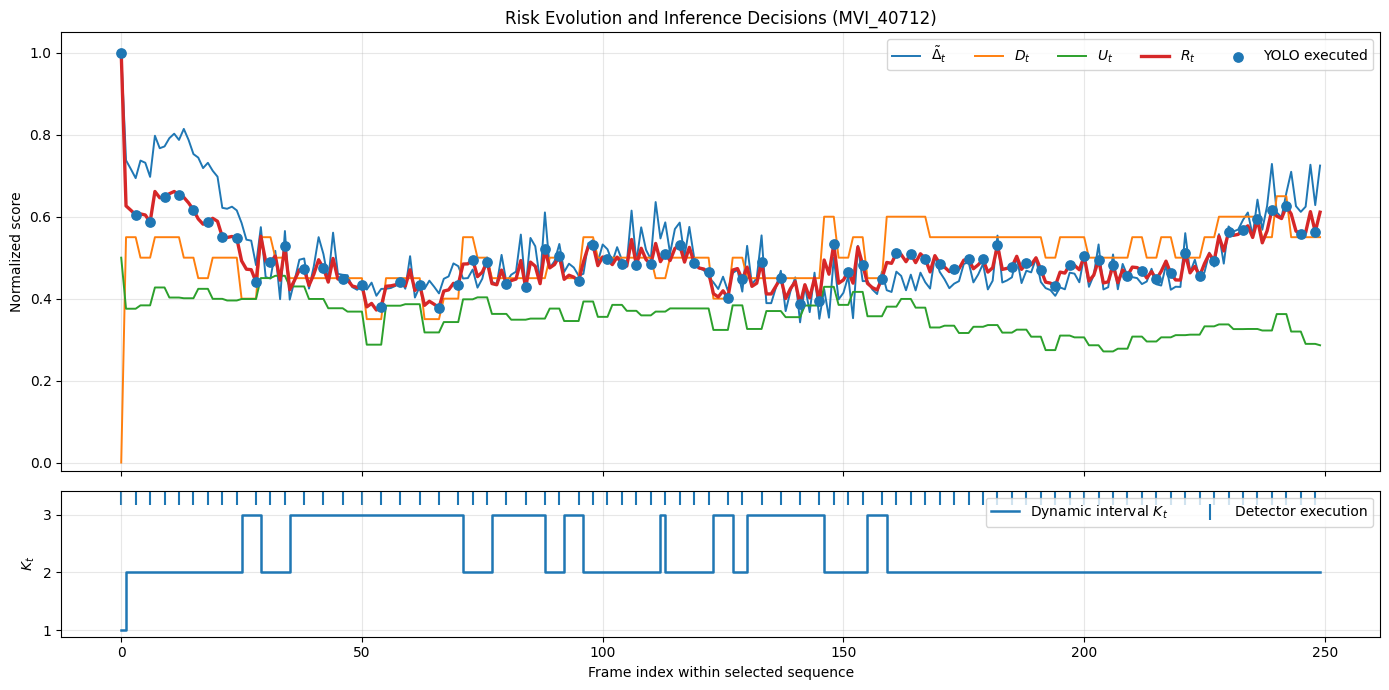

Saved: /kaggle/working/ua_detrac_event_adaptive_results/risk_timeline_two_panel.png


In [46]:
def plot_risk_timeline_two_panel(
    timeline_df,
    sequence_id,
    start=0,
    length=250,
    save_path=None
):
    seq_df = timeline_df[timeline_df["sequence_id"] == sequence_id].copy()
    seq_df = seq_df.reset_index(drop=True)

    end = min(start + length, len(seq_df))
    plot_df = seq_df.iloc[start:end].copy()

    x = np.arange(len(plot_df))

    fig, axes = plt.subplots(
        2, 1,
        figsize=(14, 7),
        sharex=True,
        gridspec_kw={"height_ratios": [3, 1]}
    )

    # Top panel
    axes[0].plot(x, plot_df["delta_norm"], linewidth=1.4, label=r"$\tilde{\Delta}_t$")
    axes[0].plot(x, plot_df["density"], linewidth=1.4, label=r"$D_t$")
    axes[0].plot(x, plot_df["uncertainty"], linewidth=1.4, label=r"$U_t$")
    axes[0].plot(x, plot_df["risk"], linewidth=2.4, label=r"$R_t$")

    yolo_mask = plot_df["run_yolo"].values == 1
    axes[0].scatter(
        x[yolo_mask],
        plot_df.loc[yolo_mask, "risk"],
        s=45,
        marker="o",
        label="YOLO executed",
        zorder=5
    )

    axes[0].set_ylabel("Normalized score")
    axes[0].set_ylim(-0.02, 1.05)
    axes[0].set_title(f"Risk Evolution and Inference Decisions ({sequence_id})")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(ncol=5, loc="upper right")

    # Bottom panel: decisions and K_t
    axes[1].step(x, plot_df["K_t"], where="post", linewidth=1.8, label=r"Dynamic interval $K_t$")
    axes[1].scatter(
        x[yolo_mask],
        np.ones(np.sum(yolo_mask)) * (plot_df["K_t"].max() + 0.3),
        marker="|",
        s=120,
        label="Detector execution"
    )

    axes[1].set_ylabel(r"$K_t$")
    axes[1].set_xlabel("Frame index within selected sequence")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend(ncol=2, loc="upper right")

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()


save_path = RESULTS_DIR / "risk_timeline_two_panel.png"

plot_risk_timeline_two_panel(
    timeline_df=timeline_df,
    sequence_id=selected_seq,
    start=0,
    length=250,
    save_path=save_path
)

print("Saved:", save_path)

# Qualitative Policy Comparison

In [76]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# =========================================================
# 1) Format correct des clés utilisées dans pred_cache/delta_cache
# =========================================================
def make_cache_key(sid, img_path):
    """
    Format compatible avec pred_cache et delta_cache:
    Exemple:
    MVI_40712/MVI_40712_img00001
    """
    return f"{sid}/{Path(img_path).stem}"


# =========================================================
# 2) Dessiner les bounding boxes
# =========================================================
def draw_boxes(img_rgb, preds, color=(255, 0, 0), thickness=2, show_conf=False):
    """
    preds format attendu:
    [x1, y1, x2, y2, conf, cls]
    """
    img = img_rgb.copy()

    if preds is None or len(preds) == 0:
        return img

    for p in preds:
        x1, y1, x2, y2, conf, cls = p
        x1, y1, x2, y2 = map(int, [x1, y1, x2, y2])

        cv2.rectangle(img, (x1, y1), (x2, y2), color, thickness)

        if show_conf:
            label = f"{conf:.2f}"
            cv2.putText(
                img,
                label,
                (x1, max(15, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                color,
                1,
                cv2.LINE_AA
            )

    return img


# =========================================================
# 3) Grouper eval_stream par séquence
# =========================================================
def group_stream_by_sequence(stream):
    seqs = {}
    for sid, img_path in stream:
        seqs.setdefault(sid, []).append(img_path)
    return seqs


# =========================================================
# 4) Vérifier si les clés existent
# =========================================================
def check_cache_keys(sequence_id, start_idx=0):
    seqs = group_stream_by_sequence(eval_stream)

    if sequence_id not in seqs:
        raise ValueError(f"Séquence introuvable: {sequence_id}")

    img_path = seqs[sequence_id][start_idx]
    key = make_cache_key(sequence_id, img_path)

    print("Image path:", img_path)
    print("Generated key:", key)
    print("In pred_cache?", key in pred_cache)
    print("In delta_cache?", key in delta_cache)


# =========================================================
# 5) Simuler RAED-VP sur 4 frames consécutives
# =========================================================
def simulate_adaptive_on_4_frames(
    sequence_id=None,
    start_idx=0,
    alpha=0.50,
    beta=0.40,
    gamma=0.10,
    delta_ref=0.0157,
    k_max=3,
    force_dense_if_cars=True,
    show_conf=False,
    save_path=None
):
    """
    Prend 4 frames consécutives, applique RAED-VP localement,
    et affiche ce qui est exécuté et ce qui est propagé.

    La première frame t est forcée comme YOLO executed,
    puis t+1, t+2, t+3 suivent la décision adaptive.
    """

    seqs = group_stream_by_sequence(eval_stream)

    if sequence_id is None:
        sequence_id = list(seqs.keys())[0]

    if sequence_id not in seqs:
        raise ValueError(f"Séquence introuvable: {sequence_id}")

    paths = seqs[sequence_id]

    if start_idx + 4 > len(paths):
        raise ValueError(
            f"start_idx trop grand. La séquence contient {len(paths)} frames."
        )

    selected_paths = paths[start_idx:start_idx + 4]

    preds_list = []
    flags_list = []
    risk_list = []
    kt_list = []
    source_list = []

    last_preds = None
    frames_since_infer = 999
    consecutive_skips = 0
    last_exec_label = None

    # Paramètres internes conservatifs
    max_consecutive_skip = 2
    motion_force_threshold = 0.60

    for j, img_path in enumerate(selected_paths):
        key = make_cache_key(sequence_id, img_path)

        if key not in pred_cache:
            raise KeyError(f"Clé absente de pred_cache: {key}")

        if key not in delta_cache:
            raise KeyError(f"Clé absente de delta_cache: {key}")

        frame_label = "t" if j == 0 else f"t+{j}"

        # Première frame : on force YOLO
        if j == 0:
            run = True
            risk = 1.0
            k_t = 1

        else:
            delta = delta_cache[key]

            risk = adaptive_risk(
                delta=delta,
                last_preds=last_preds,
                alpha=alpha,
                beta=beta,
                gamma=gamma,
                delta_ref=delta_ref
            )

            k_t = dynamic_interval_from_risk(
                risk=risk,
                k_min=K_MIN,
                k_max=k_max
            )

            delta_norm = normalize_delta(delta, delta_ref)
            density = vehicle_density_score(last_preds)

            # Si scène dense, on limite l'intervalle
            if force_dense_if_cars and density >= 0.50:
                k_t = min(k_t, 2)

            # Décision finale
            if delta_norm > motion_force_threshold:
                run = True
            elif consecutive_skips >= max_consecutive_skip:
                run = True
            else:
                run = frames_since_infer >= k_t

        if run:
            preds = pred_cache[key]
            last_preds = preds
            frames_since_infer = 0
            consecutive_skips = 0
            flag = 1
            last_exec_label = frame_label
            source = "YOLO executed"
        else:
            preds = last_preds if last_preds is not None else np.zeros((0, 6), dtype=np.float32)
            frames_since_infer += 1
            consecutive_skips += 1
            flag = 0
            source = f"Propagated from {last_exec_label}"

        preds_list.append(preds)
        flags_list.append(flag)
        risk_list.append(risk)
        kt_list.append(k_t)
        source_list.append(source)

    # =====================================================
    # Affichage des 4 frames
    # =====================================================
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))

    for j, img_path in enumerate(selected_paths):
        img_bgr = cv2.imread(str(img_path))

        if img_bgr is None:
            raise ValueError(f"Image non lisible: {img_path}")

        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        img_draw = draw_boxes(
            img_rgb,
            preds_list[j],
            color=(255, 0, 0),
            thickness=2,
            show_conf=show_conf
        )

        frame_label = "t" if j == 0 else f"t+{j}"

        axes[j].imshow(img_draw)
        axes[j].set_title(
            f"{frame_label}\n{source_list[j]}\n"
            f"R={risk_list[j]:.2f}, K={kt_list[j]}",
            fontsize=10
        )
        axes[j].axis("off")

    plt.suptitle(
        f"RAED-VP qualitative behavior on 4 consecutive frames | {sequence_id}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout(rect=[0, 0, 1, 0.90])

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

    # =====================================================
    # Affichage texte des décisions
    # =====================================================
    print("Sequence:", sequence_id)
    print("Start index:", start_idx)
    print("-" * 70)

    for j, img_path in enumerate(selected_paths):
        frame_label = "t" if j == 0 else f"t+{j}"
        print(
            f"{frame_label} | {Path(img_path).name} | "
            f"{source_list[j]} | "
            f"flag={flags_list[j]} | "
            f"R={risk_list[j]:.3f} | "
            f"K={kt_list[j]}"
        )

Image path: /kaggle/working/data/images/val/MVI_40712_img00001.jpg
Generated key: MVI_40712/MVI_40712_img00001
In pred_cache? True
In delta_cache? True


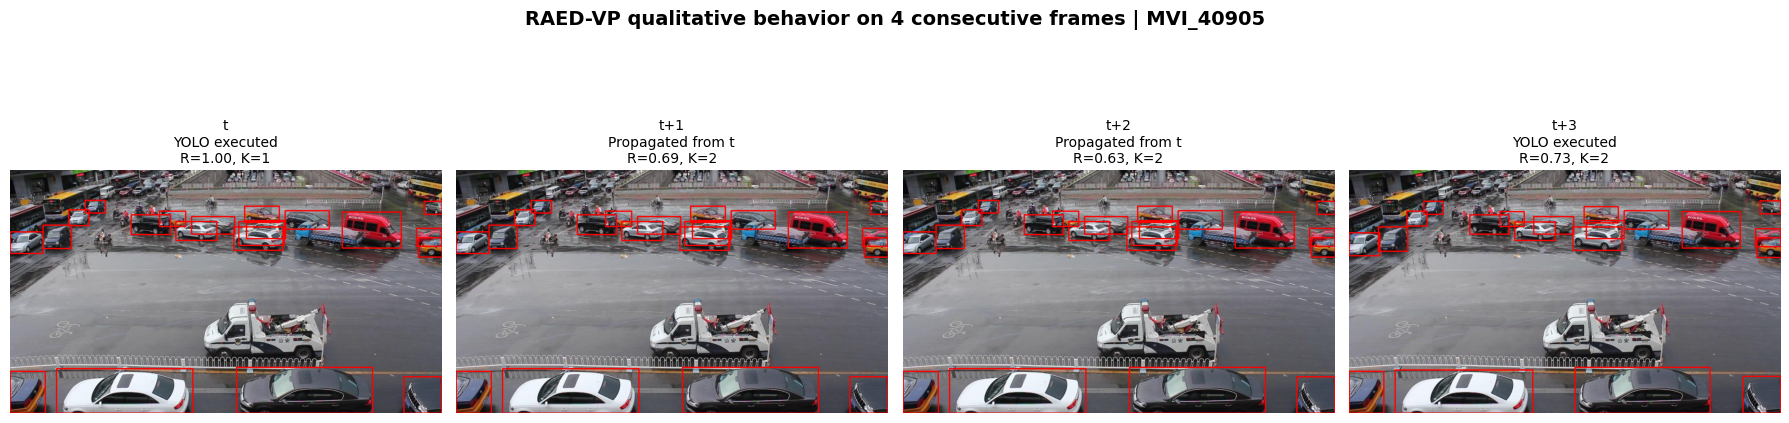

Sequence: MVI_40905
Start index: 0
----------------------------------------------------------------------
t | MVI_40905_img00001.jpg | YOLO executed | flag=1 | R=1.000 | K=1
t+1 | MVI_40905_img00002.jpg | Propagated from t | flag=0 | R=0.686 | K=2
t+2 | MVI_40905_img00003.jpg | Propagated from t | flag=0 | R=0.630 | K=2
t+3 | MVI_40905_img00004.jpg | YOLO executed | flag=1 | R=0.730 | K=2


In [78]:
# Vérifier d'abord que les clés existent
check_cache_keys(sequence_id="MVI_40712", start_idx=0)

# Générer la figure qualitative
simulate_adaptive_on_4_frames(
    sequence_id="MVI_40905",
    start_idx=0,
    alpha=0.50,
    beta=0.40,
    gamma=0.10,
    delta_ref=0.0157,
    k_max=3,
    save_path=RESULTS_DIR / "raed_vp_qualitative_4frames.png",
    show_conf=False
)

# GPU computational cost 

In [79]:
def compute_cpu_cost_summary(
    policy_name,
    infer_flags,
    latency_cache,
    scheduler_latency_per_frame=0.001
):
    """
    Computes GPU computational cost proxy for an inference policy.

    Parameters
    ----------
    policy_name : str
        Name of the policy.
    infer_flags : dict
        key -> 1 if YOLO was executed, 0 if prediction was propagated.
    latency_cache : dict
        key -> measured detector latency in seconds.
    scheduler_latency_per_frame : float
        Estimated lightweight scheduling overhead per frame in seconds.

    Returns
    -------
    dict
        CPU cost summary.
    """
    total_frames = len(infer_flags)
    yolo_frames = int(sum(infer_flags.values()))
    skipped_frames = total_frames - yolo_frames

    detector_time = 0.0
    for key, flag in infer_flags.items():
        if flag == 1:
            detector_time += float(latency_cache[key])

    scheduler_time = total_frames * scheduler_latency_per_frame
    total_cpu_time = detector_time + scheduler_time

    return {
        "policy": policy_name,
        "total_frames": total_frames,
        "yolo_frames": yolo_frames,
        "skipped_frames": skipped_frames,
        "detector_cpu_time_s": detector_time,
        "scheduler_cpu_time_s": scheduler_time,
        "total_cpu_time_s": total_cpu_time,
        "cpu_cost_proxy": total_cpu_time
    }


cpu_cont = compute_cpu_cost_summary(
    "Continuous",
    eval_cont_flags,
    eval_latency,
    scheduler_latency_per_frame=0.001
)

cpu_event = compute_cpu_cost_summary(
    "Event-driven",
    eval_event_flags,
    eval_latency,
    scheduler_latency_per_frame=0.001
)

cpu_adapt = compute_cpu_cost_summary(
    "Adaptive",
    eval_adapt_flags,
    eval_latency,
    scheduler_latency_per_frame=0.001
)

cpu_cost_df = pd.DataFrame([cpu_cont, cpu_event, cpu_adapt])

continuous_cpu_time = cpu_cost_df.loc[
    cpu_cost_df["policy"] == "Continuous",
    "total_cpu_time_s"
].values[0]

cpu_cost_df["cpu_time_reduction_vs_continuous"] = (
    1.0 - cpu_cost_df["total_cpu_time_s"] / continuous_cpu_time
)

cpu_cost_df["detector_call_reduction"] = (
    1.0 - cpu_cost_df["yolo_frames"] / cpu_cost_df.loc[
        cpu_cost_df["policy"] == "Continuous",
        "yolo_frames"
    ].values[0]
)

display(cpu_cost_df)

cpu_cost_df.to_csv(RESULTS_DIR / "cpu_computational_cost_summary.csv", index=False)
print("Saved:", RESULTS_DIR / "cpu_computational_cost_summary.csv")

,policy,total_frames,yolo_frames,skipped_frames,detector_cpu_time_s,scheduler_cpu_time_s,total_cpu_time_s,cpu_cost_proxy,cpu_time_reduction_vs_continuous,detector_call_reduction
0,Continuous,44204,44204,0,582.853462,44.204,627.057462,627.057462,0.000000,0.000000
1,Event-driven,44204,18381,25823,242.394284,44.204,286.598284,286.598284,0.542947,0.584178
2,Adaptive,44204,14320,29884,188.806758,44.204,233.010758,233.010758,0.628406,0.676047


Saved: /kaggle/working/ua_detrac_event_adaptive_results/cpu_computational_cost_summary.csv


# Condition Sequences

In [80]:
from pathlib import Path
import xml.etree.ElementTree as ET
from collections import defaultdict

# =====================================================
# Path vers les annotations XML
# =====================================================

xml_dir = Path(
    "/kaggle/input/datasets/bratjay/ua-detrac-orig/"
    "DETRAC-Test-Annotations-XML/DETRAC-Test-Annotations-XML"
)

# =====================================================
# Lire la condition météo depuis chaque XML
# =====================================================

def extract_weather_from_xml(xml_path):
    """
    Extract sequence name and weather condition from UA-DETRAC XML.

    UA-DETRAC uses the attribute name 'sence_weather'
    inside <sequence_attribute ... />.
    """
    tree = ET.parse(xml_path)
    root = tree.getroot()

    sequence_name = root.attrib.get("name", xml_path.stem)

    seq_attr = root.find("sequence_attribute")
    if seq_attr is None:
        return sequence_name, "unknown"

    weather = seq_attr.attrib.get("sence_weather", "unknown")
    weather = weather.strip().lower()

    return sequence_name, weather


# =====================================================
# Construire condition_sequences automatiquement
# =====================================================

condition_sequences = defaultdict(list)

for xml_path in sorted(xml_dir.glob("*.xml")):
    seq_name, weather = extract_weather_from_xml(xml_path)
    condition_sequences[weather].append(seq_name)

condition_sequences = dict(condition_sequences)

# Affichage
for condition, seqs in condition_sequences.items():
    print(f"{condition}: {len(seqs)} sequences")
    print(seqs[:10])
    print("-" * 60)

sunny: 8 sequences
['MVI_39031', 'MVI_39051', 'MVI_39211', 'MVI_39271', 'MVI_39311', 'MVI_39361', 'MVI_39371', 'MVI_39401']
------------------------------------------------------------
cloudy: 11 sequences
['MVI_39501', 'MVI_39511', 'MVI_40701', 'MVI_40711', 'MVI_40712', 'MVI_40714', 'MVI_40851', 'MVI_40852', 'MVI_40853', 'MVI_40854']
------------------------------------------------------------
night: 12 sequences
['MVI_40742', 'MVI_40743', 'MVI_40761', 'MVI_40762', 'MVI_40763', 'MVI_40771', 'MVI_40772', 'MVI_40773', 'MVI_40774', 'MVI_40775']
------------------------------------------------------------
rainy: 9 sequences
['MVI_40863', 'MVI_40864', 'MVI_40891', 'MVI_40892', 'MVI_40901', 'MVI_40902', 'MVI_40903', 'MVI_40904', 'MVI_40905']
------------------------------------------------------------


In [81]:
wanted_conditions = ["sunny", "cloudy", "rainy", "night"]

condition_sequences = {
    cond: condition_sequences.get(cond, [])
    for cond in wanted_conditions
}

for condition, seqs in condition_sequences.items():
    print(f"{condition}: {len(seqs)} sequences")
    print(seqs[:10])

sunny: 8 sequences
['MVI_39031', 'MVI_39051', 'MVI_39211', 'MVI_39271', 'MVI_39311', 'MVI_39361', 'MVI_39371', 'MVI_39401']
cloudy: 11 sequences
['MVI_39501', 'MVI_39511', 'MVI_40701', 'MVI_40711', 'MVI_40712', 'MVI_40714', 'MVI_40851', 'MVI_40852', 'MVI_40853', 'MVI_40854']
rainy: 9 sequences
['MVI_40863', 'MVI_40864', 'MVI_40891', 'MVI_40892', 'MVI_40901', 'MVI_40902', 'MVI_40903', 'MVI_40904', 'MVI_40905']
night: 12 sequences
['MVI_40742', 'MVI_40743', 'MVI_40761', 'MVI_40762', 'MVI_40763', 'MVI_40771', 'MVI_40772', 'MVI_40773', 'MVI_40774', 'MVI_40775']


In [82]:
# Séquences réellement utilisées dans eval_stream
eval_sequences = sorted(set([sid for sid, _ in eval_stream]))

condition_sequences_eval = {}

for condition, seqs in condition_sequences.items():
    seqs_eval = [s for s in seqs if s in eval_sequences]
    condition_sequences_eval[condition] = seqs_eval

print("Condition sequences used in evaluation:")
for condition, seqs in condition_sequences_eval.items():
    print(f"{condition}: {len(seqs)} sequences")
    print(seqs)
    print("-" * 60)

Condition sequences used in evaluation:
sunny: 0 sequences
[]
------------------------------------------------------------
cloudy: 11 sequences
['MVI_39501', 'MVI_39511', 'MVI_40701', 'MVI_40711', 'MVI_40712', 'MVI_40714', 'MVI_40851', 'MVI_40852', 'MVI_40853', 'MVI_40854', 'MVI_40855']
------------------------------------------------------------
rainy: 9 sequences
['MVI_40863', 'MVI_40864', 'MVI_40891', 'MVI_40892', 'MVI_40901', 'MVI_40902', 'MVI_40903', 'MVI_40904', 'MVI_40905']
------------------------------------------------------------
night: 12 sequences
['MVI_40742', 'MVI_40743', 'MVI_40761', 'MVI_40762', 'MVI_40763', 'MVI_40771', 'MVI_40772', 'MVI_40773', 'MVI_40774', 'MVI_40775', 'MVI_40792', 'MVI_40793']
------------------------------------------------------------


In [83]:
condition_sequences = condition_sequences_eval

In [85]:
def make_cache_key(sid, img_path):
    """
    Format utilisé dans pred_cache, delta_cache, eval_gt, eval_latency, etc.
    Exemple:
    MVI_39031/MVI_39031_img00001
    """
    return f"{sid}/{Path(img_path).stem}"


def filter_stream_by_sequences(stream, sequence_list):
    """
    Garde uniquement les frames appartenant aux séquences demandées.
    """
    seq_set = set(sequence_list)
    return [(sid, img_path) for sid, img_path in stream if sid in seq_set]


def filter_dict_by_stream(data_dict, stream):
    """
    Filtre un dictionnaire en gardant seulement les clés présentes dans stream.
    """
    keys = set(make_cache_key(sid, img_path) for sid, img_path in stream)
    return {k: v for k, v in data_dict.items() if k in keys}

In [86]:
condition_rows = []

for condition, seq_list in condition_sequences.items():

    if len(seq_list) == 0:
        print(f"[SKIP] {condition}: no sequences in evaluation split.")
        continue

    cond_stream = filter_stream_by_sequences(eval_stream, seq_list)

    if len(cond_stream) == 0:
        print(f"[SKIP] {condition}: no frames found in eval_stream.")
        continue

    print(f"\nCondition: {condition}")
    print(f"Sequences: {len(seq_list)}")
    print(f"Frames: {len(cond_stream)}")

    # Filtrer GT et latences
    cond_gt = filter_dict_by_stream(eval_gt, cond_stream)
    cond_latency = filter_dict_by_stream(eval_latency, cond_stream)

    # Continuous
    cond_cont_preds = filter_dict_by_stream(eval_cont_preds, cond_stream)
    cond_cont_flags = filter_dict_by_stream(eval_cont_flags, cond_stream)

    # Event-driven
    cond_event_preds = filter_dict_by_stream(eval_event_preds, cond_stream)
    cond_event_flags = filter_dict_by_stream(eval_event_flags, cond_stream)

    # Adaptive
    cond_adapt_preds = filter_dict_by_stream(eval_adapt_preds, cond_stream)
    cond_adapt_flags = filter_dict_by_stream(eval_adapt_flags, cond_stream)

    policies = [
        ("Continuous", cond_cont_preds, cond_cont_flags),
        ("Event-driven", cond_event_preds, cond_event_flags),
        ("Adaptive", cond_adapt_preds, cond_adapt_flags),
    ]

    for policy_name, preds, flags in policies:
        summary = summarize_policy(
            policy_name,
            cond_stream,
            preds,
            flags,
            cond_gt,
            cond_latency
        )

        summary["condition"] = condition
        summary["num_sequences"] = len(seq_list)
        summary["num_frames_condition"] = len(cond_stream)

        condition_rows.append(summary)

condition_df = pd.DataFrame(condition_rows)

display(condition_df)

condition_df.to_csv(
    RESULTS_DIR / "condition_wise_policy_results.csv",
    index=False
)

print("Saved:", RESULTS_DIR / "condition_wise_policy_results.csv")

[SKIP] sunny: no sequences in evaluation split.

Condition: cloudy
Sequences: 11
Frames: 12825


/tmp/ipykernel_57/4064674785.py:27: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ap = np.trapz(np.interp(x, mrec, mpre), x)



Condition: rainy
Sequences: 9
Frames: 12900

Condition: night
Sequences: 12
Frames: 18479


,policy,mAP50,mAP50_95,precision,recall,f1,count_MAE,temporal_stability,total_frames,yolo_frames,skipped_frames,frames_processed_ratio,frame_reduction,estimated_total_time_s,estimated_yolo_time_s,mean_latency_per_frame_ms,effective_fps,condition,num_sequences,num_frames_condition
0,Continuous,0.909259,0.698994,0.696998,0.935833,0.798948,5.220429,1.0,12825,12825,0,1.000000,0.000000,179.462632,166.637632,13.993188,71.463345,cloudy,11,12825
1,Event-driven,0.908659,0.654040,0.696529,0.935542,0.798534,5.226199,1.0,12825,4661,8164,0.363431,0.636569,73.358573,60.533573,5.719967,174.826192,cloudy,11,12825
2,Adaptive,0.908655,0.651264,0.696700,0.935463,0.798618,5.220585,1.0,12825,4265,8560,0.332554,0.667446,68.235361,55.410361,5.320496,187.952403,cloudy,11,12825
3,Continuous,0.756986,0.571944,0.719772,0.738890,0.729206,4.317209,1.0,12900,12900,0,1.000000,0.000000,184.939250,172.039250,14.336376,69.752635,rainy,9,12900
4,Event-driven,0.755894,0.543020,0.718323,0.737610,0.727838,4.322713,1.0,12900,5599,7301,0.434031,0.565969,87.552481,74.652481,6.787014,147.340199,rainy,9,12900
5,Adaptive,0.756672,0.530970,0.719179,0.738009,0.728472,4.304419,1.0,12900,4260,8640,0.330233,0.669767,69.731160,56.831160,5.405516,184.996206,rainy,9,12900
6,Continuous,0.887035,0.675916,0.742292,0.881014,0.805726,2.357270,1.0,18479,18479,0,1.000000,0.000000,262.655579,244.176579,14.213733,70.354493,night,12,18479
7,Event-driven,0.885372,0.639675,0.740399,0.878664,0.803627,2.355755,1.0,18479,8121,10358,0.439472,0.560528,125.687230,107.208230,6.801625,147.023688,night,12,18479
8,Adaptive,0.883120,0.614762,0.738145,0.876139,0.801244,2.353320,1.0,18479,5795,12684,0.313599,0.686401,95.044238,76.565238,5.143365,194.425253,night,12,18479


Saved: /kaggle/working/ua_detrac_event_adaptive_results/condition_wise_policy_results.csv


In [87]:
condition_table_df = condition_df[
    [
        "condition",
        "policy",
        "num_sequences",
        "num_frames_condition",
        "mAP50",
        "mAP50_95",
        "precision",
        "recall",
        "f1",
        "count_MAE",
        "temporal_stability",
        "yolo_frames",
        "skipped_frames",
        "frame_reduction",
        "mean_latency_per_frame_ms",
        "effective_fps",
    ]
].copy()

condition_table_df["mAP50_percent"] = condition_table_df["mAP50"] * 100
condition_table_df["recall_percent"] = condition_table_df["recall"] * 100
condition_table_df["f1_percent"] = condition_table_df["f1"] * 100
condition_table_df["frame_reduction_percent"] = condition_table_df["frame_reduction"] * 100

condition_table_compact = condition_table_df[
    [
        "condition",
        "policy",
        "num_sequences",
        "num_frames_condition",
        "mAP50_percent",
        "recall_percent",
        "f1_percent",
        "frame_reduction_percent",
        "mean_latency_per_frame_ms",
        "effective_fps",
        "temporal_stability",
    ]
].copy()

display(condition_table_compact)

condition_table_compact.to_csv(
    RESULTS_DIR / "condition_wise_summary_compact.csv",
    index=False
)

print("Saved:", RESULTS_DIR / "condition_wise_summary_compact.csv")

,condition,policy,num_sequences,num_frames_condition,mAP50_percent,recall_percent,f1_percent,frame_reduction_percent,mean_latency_per_frame_ms,effective_fps,temporal_stability
0,cloudy,Continuous,11,12825,90.925872,93.583340,79.894847,0.000000,13.993188,71.463345,1.0
1,cloudy,Event-driven,11,12825,90.865894,93.554241,79.853412,63.656920,5.719967,174.826192,1.0
2,cloudy,Adaptive,11,12825,90.865530,93.546305,79.861785,66.744639,5.320496,187.952403,1.0
3,rainy,Continuous,9,12900,75.698582,73.888977,72.920569,0.000000,14.336376,69.752635,1.0
4,rainy,Event-driven,9,12900,75.589379,73.760987,72.783845,56.596899,6.787014,147.340199,1.0
5,rainy,Adaptive,9,12900,75.667209,73.800916,72.847228,66.976744,5.405516,184.996206,1.0
6,night,Continuous,12,18479,88.703509,88.101449,80.572602,0.000000,14.213733,70.354493,1.0
7,night,Event-driven,12,18479,88.537238,87.866380,80.362748,56.052817,6.801625,147.023688,1.0
8,night,Adaptive,12,18479,88.312016,87.613873,80.124392,68.640078,5.143365,194.425253,1.0


Saved: /kaggle/working/ua_detrac_event_adaptive_results/condition_wise_summary_compact.csv
